# Исходные данные

In [82]:
# В качестве датасета используется описанный в лабораторной работе № 3 набор данных о пингвинах 
# Проделаем все операции по подготовки датасета в соответствии с описанием в лабораторной работе 3
import pandas as pd
PATH = "data/penguins.csv"
df = pd.read_csv(PATH)
df = df.dropna().reset_index(drop=True)
display(df.head(5))
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    str    
 1   island             333 non-null    str    
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    str    
 7   year               333 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 20.9 KB


In [83]:
# Оставляем только числовые признаки
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
scaled_data = df[features]

x = scaled_data # входные признаки
y = df["species"] # Целевой признак - species (разновидность) пингвина

# Разделим данные на тренировочные и тестовые,
# добавим random_state для воспроизводимости выборки
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

# Вспомогательные функции

In [116]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import multilabel_confusion_matrix

# Реализуем функции для удобного вывода метрик

# Показывает основные метрики модели
def show_metrics(y_test, predictions, average, label):
    precision = precision_score(y_test, predictions, average=average, zero_division=0)
    recall = recall_score(y_test, predictions, average=average, zero_division=0)
    f1 = f1_score(y_test, predictions, average=average, zero_division=0)
    print(label)
    print(f"Accuracy = {acc}\nPrecision = {precision}\nRecall = {recall}\nF1 Score = {f1}")

# Принимает словарь {название: модель} и показывает все метрики для каждой модели в удобном виде 
def show_metrics(models, x_test, y_test, average="macro"):
    rows = []

    for name, model in models.items():
        predictions = model.predict(x_test)

        rows.append({
             "Модель": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, average=average, zero_division=0),
            "Recall": recall_score(y_test, predictions, average=average, zero_division=0),
            "F1": f1_score(y_test, predictions, average=average, zero_division=0),
        })

    metrics_df = pd.DataFrame(rows).set_index("Модель")
    display(metrics_df)

# Показывает матрицу ошибок
def show_confusion_matrix(model, y_test, predictions, label):
    labels = model.classes_
    cm = confusion_matrix(y_test, predictions, labels=labels)
    print(label)
    display(pd.DataFrame(
        cm,
        index=pd.Index(labels, name="Истинный вид"),
        columns=pd.Index(labels, name="Предсказанный вид")
    ))

# Показывает элементы матрицы ошибок для каждого класса
def show_confusion_counts(model, y_test, predictions, label):
    labels = model.classes_
    matrices = multilabel_confusion_matrix(y_test, predictions, labels=labels)
    print(label)
    for label_row, matrix in zip(labels, matrices):
        tn, fp, fn, tp = matrix.ravel()
        print(f"{label_row}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Реализуем функции для удобного вывода ROC-кривых

# Выводит ROC-кривые для всех классов
def draw_all_rocs(model, x_test, y_test, title, ax):
    classes = model.classes_
    probabilities = model.predict_proba(x_test) # получаем оценки вероятности принадлежности пингвина к каждому классу
    y_test_binary = label_binarize(y_test, classes=classes) # Отдельный бинарный целевой признак для каждого вида
    
    for i, species in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_binary[:, i],probabilities[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr,label=f"{species} (AUC = {roc_auc:.3f})")
        
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

# Возвращает посчитанную усредненную ROC-кривую по всем классам модели
def count_median_roc(model, x_test, y_test):
    classes = model.classes_
    probabilities = model.predict_proba(x_test)
    y_test_binary = label_binarize(y_test, classes=classes)
    fpr_grid = np.linspace(0, 1, 1000) # общая сетка значений от 0 до 1
    tpr_values = []

    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_test_binary[:, i],probabilities[:, i])
        interpolated_tpr = np.interp(fpr_grid, fpr, tpr) # вычисляем TPR каждой кривой на общей сетке FPR
        tpr_values.append(interpolated_tpr)

    mean_tpr = np.mean(tpr_values, axis=0) # среднее TPR классов для каждой точки сетки

    fpr_grid = np.r_[0.0, fpr_grid]
    mean_tpr = np.r_[0.0, mean_tpr]
    
    macro_auc = auc(fpr_grid, mean_tpr)

    return fpr_grid, mean_tpr, macro_auc

# Вывод график с усредненной ROC-кривой
def draw_median_roc(model, x_test, y_test, title, ax):
    fpr_grid, mean_tpr, macro_auc = count_median_roc(model, x_test, y_test)
    ax.plot(
        fpr_grid,
        mean_tpr,
        label=f"ROC-кривая (AUC = {macro_auc:.3f})"
    )
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate (FPR)")
    ax.set_ylabel("True Positive Rate (TPR)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

# Выводит на одном графике усредненные ROC-кривые для различных моделей
def show_all_median_roc(models):
    plt.figure(figsize=(14, 14))

    for name, model in models.items():
        fpr_grid, mean_tpr, macro_auc = count_median_roc(model, x_test, y_test)
        plt.plot(
            fpr_grid,
            mean_tpr,
            label=f"{name} (AUC = {macro_auc:.3f})"
        )
        

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.title("ROC-кривые средних значений")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# Сравнение моделей

In [92]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Объявим все модели классификаторов для проведения сравнения

# K-ближайших соседей k=2
model_knn_k2 = KNeighborsClassifier(n_neighbors=2) # n=2, получено в лабораторной работе 4
model_knn_k2.fit(x_train, y_train)

# K-ближайших соседей k=3
model_knn_k3 = KNeighborsClassifier(n_neighbors=3) 
model_knn_k3.fit(x_train, y_train)

# K-ближайших соседей k=5
model_knn_k5 = KNeighborsClassifier(n_neighbors=5) 
model_knn_k5.fit(x_train, y_train)

# Случайный лес n=10
model_rf_n10 = RandomForestClassifier(n_estimators=10, random_state=42) 
model_rf_n10.fit(x_train, y_train)

# Случайный лес n=20
model_rf_n20 = RandomForestClassifier(n_estimators=20, random_state=42) 
model_rf_n20.fit(x_train, y_train)

# Случайный лес n=30
model_rf_n30 = RandomForestClassifier(n_estimators=30, random_state=42) 
model_rf_n30.fit(x_train, y_train)

# Случайный лес n=20 max_depth=1
model_rf_md2 = RandomForestClassifier(n_estimators=20, max_depth=2, random_state=42)
model_rf_md2.fit(x_train, y_train)

# Случайный лес n=20 max_depth=5
model_rf_md5 = RandomForestClassifier(n_estimators=20, max_depth=5, random_state=42)
model_rf_md5.fit(x_train, y_train)

# Случайный лес n=20 max_depth=10
model_rf_md10 = RandomForestClassifier(n_estimators=20, max_depth=10, random_state=42)
model_rf_md10.fit(x_train, y_train)


# Словарь для удобного сравнения моделей
models = {
    "KNN k=2": model_knn_k2,
    "KNN k=3": model_knn_k3,
    "KNN k=5": model_knn_k5,
    "Random Forest n=10": model_rf_n10,
    "Random Forest n=20": model_rf_n20,
    "Random Forest n=30": model_rf_n30,
    "Random Forest max_depth=2": model_rf_md2,
    "Random Forest max_depth=5": model_rf_md5,
    "Random Forest max_depth=10": model_rf_md10,
}

## Сравнение метрик

In [93]:
show_metrics(models, x_test, y_test)

,Accuracy,Precision,Recall,F1
Модель,,,,
KNN k=2,0.772727,0.746346,0.700824,0.693930
KNN k=3,0.727273,0.688341,0.689542,0.681467
KNN k=5,0.745455,0.727595,0.702362,0.699471
Random Forest n=10,0.963636,0.976190,0.946667,0.958669
Random Forest n=20,0.981818,0.980256,0.980256,0.980256
Random Forest n=30,0.972727,0.981818,0.960000,0.969378
Random Forest max_depth=2,0.963636,0.966989,0.953590,0.959644
Random Forest max_depth=5,0.981818,0.980256,0.980256,0.980256
Random Forest max_depth=10,0.981818,0.980256,0.980256,0.980256


**Разбор результатов**

Среди моделей k-ближайших соседей наибольшая Accuracy получена при k=2: 0.773, тогда как при k=3 и k=5 она составляет 0.727 и 0.745 соответственно. Однако по macro F1 немного лучше вариант k=5 (0.699 против 0.694 при k=2). Поэтому выбор лучшего k зависит от метрики: максимальная доля правильных ответов и наиболее сбалансированное качество по классам достигаются при разных значениях параметра.

Все рассмотренные варианты случайного леса превосходят KNN по Accuracy и macro F1. Лучший результат по этим метрикам получен при 20 деревьях без ограничения глубины, а также при max_depth=5 и max_depth=10: Accuracy=0.982, macro F1=0.980. Увеличение числа деревьев до 30 не улучшает эти показатели, а ограничение глубины до 2 снижает Accuracy до 0.964.

Выводы относятся к текущей тестовой выборке из 110 объектов. Разница между Accuracy=0.982 и 0.973 соответствует всего одному объекту, поэтому для устойчивого выбора параметров нужна дополнительная проверка на кросс-валидации.

In [94]:
from sklearn.metrics import classification_report
for name, model in models.items():
    print(f" Модель {name} ".center(54,"="))
    predictions = model.predict(x_test)
    print(classification_report(y_test, predictions))


=================== Модель KNN k=2 ===================
              precision    recall  f1-score   support

      Adelie       0.73      0.92      0.81        52
   Chinstrap       0.60      0.24      0.34        25
      Gentoo       0.91      0.94      0.93        33

    accuracy                           0.77       110
   macro avg       0.75      0.70      0.69       110
weighted avg       0.75      0.77      0.74       110

=================== Модель KNN k=3 ===================
              precision    recall  f1-score   support

      Adelie       0.74      0.77      0.75        52
   Chinstrap       0.53      0.36      0.43        25
      Gentoo       0.79      0.94      0.86        33

    accuracy                           0.73       110
   macro avg       0.69      0.69      0.68       110
weighted avg       0.71      0.73      0.71       110

=================== Модель KNN k=5 ===================
              precision    recall  f1-score   support

      Adelie      

**Разбор результатов**

Отчёты по отдельным классам показывают, что основная проблема KNN - это распознавание вида Chinstrap. При k=2 его Recall составляет 0.24: модель находит только 6 из 25 пингвинов этого вида. При k=3 и k=5 Recall повышается до 0.36, но остаётся заметно ниже показателей остальных классов. Для Gentoo все три модели KNN имеют Recall около 0.94.

Случайный лес распознаёт Gentoo без ошибок во всех рассмотренных конфигурациях: Precision, Recall и F1 равны 1.00. При 20 деревьях, а также при max_depth=5 и max_depth=10, F1 для Adelie составляет около 0.98, для Chinstrap - 0.96. Таким образом, высокое общее качество этих моделей сопровождается высокими показателями каждого класса.

В тестовой выборке классы представлены неравномерно: 52 объекта Adelie, 25 Chinstrap и 33 Gentoo. Macro avg учитывает каждый класс с одинаковым весом, а weighted avg - пропорционально его численности. Поэтому низкое качество распознавания Chinstrap у KNN сильнее отражается на macro Recall и macro F1, чем на Accuracy.

In [95]:
for name, model in models.items():
    predictions = model.predict(x_test)
    show_confusion_matrix(model, y_test, predictions, f"Модель {name}")

Модель KNN k=2


Предсказанный вид,Adelie,Chinstrap,Gentoo
Истинный вид,,,
Adelie,48,3,1
Chinstrap,17,6,2
Gentoo,1,1,31


Модель KNN k=3


Предсказанный вид,Adelie,Chinstrap,Gentoo
Истинный вид,,,
Adelie,40,7,5
Chinstrap,13,9,3
Gentoo,1,1,31


Модель KNN k=5


...

Предсказанный вид,Adelie,Chinstrap,Gentoo
Истинный вид,,,
Adelie,51,1,0
Chinstrap,3,22,0
Gentoo,0,0,33


Модель Random Forest max_depth=5


Предсказанный вид,Adelie,Chinstrap,Gentoo
Истинный вид,,,
Adelie,51,1,0
Chinstrap,1,24,0
Gentoo,0,0,33


Модель Random Forest max_depth=10


Предсказанный вид,Adelie,Chinstrap,Gentoo
Истинный вид,,,
Adelie,51,1,0
Chinstrap,1,24,0
Gentoo,0,0,33


**Разбор результатов**

В матрицах ошибок строки соответствуют истинным видам, а столбцы предсказанным. На главной диагонали находятся правильные ответы. KNN при k=2 правильно классифицирует 85 из 110 объектов, при k=3 - 80, при k=5 - 82. Основная ошибка KNN - отнесение Chinstrap к Adelie: таких случаев 17, 13 и 14 соответственно.

У случайного леса ошибки сосредоточены между Adelie и Chinstrap, а все 33 объекта Gentoo распознаются верно. Модели с 20 деревьями, max_depth=5 и max_depth=10 имеют одинаковые матрицы: 51 правильный ответ для Adelie, 24 для Chinstrap и 33 для Gentoo. Каждая из них допускает две ошибки: один Adelie отнесён к Chinstrap и один Chinstrap - к Adelie.

Лес из 10 деревьев ошибается на четырёх объектах Chinstrap, относя их к Adelie; лес из 30 деревьев - на трёх. Это объясняет различия Accuracy и показывает, какие именно классы влияют на итоговое качество.

In [96]:
for name, model in models.items():
    predictions = model.predict(x_test)
    show_confusion_counts(model, y_test, predictions, f"Модель {name}")
    print()

Модель KNN k=2
Adelie: TN=40, FP=18, FN=4, TP=48
Chinstrap: TN=81, FP=4, FN=19, TP=6
Gentoo: TN=74, FP=3, FN=2, TP=31

Модель KNN k=3
Adelie: TN=44, FP=14, FN=12, TP=40
Chinstrap: TN=77, FP=8, FN=16, TP=9
Gentoo: TN=69, FP=8, FN=2, TP=31

Модель KNN k=5
Adelie: TN=42, FP=16, FN=10, TP=42
Chinstrap: TN=80, FP=5, FN=16, TP=9
Gentoo: TN=70, FP=7, FN=2, TP=31

Модель Random Forest n=10
Adelie: TN=54, FP=4, FN=0, TP=52
Chinstrap: TN=85, FP=0, FN=4, TP=21
Gentoo: TN=77, FP=0, FN=0, TP=33

Модель Random Forest n=20
Adelie: TN=57, FP=1, FN=1, TP=51
Chinstrap: TN=84, FP=1, FN=1, TP=24
Gentoo: TN=77, FP=0, FN=0, TP=33

Модель Random Forest n=30
Adelie: TN=55, FP=3, FN=0, TP=52
Chinstrap: TN=85, FP=0, FN=3, TP=22
Gentoo: TN=77, FP=0, FN=0, TP=33

Модель Random Forest max_depth=2
Adelie: TN=55, FP=3, FN=1, TP=51
Chinstrap: TN=84, FP=1, FN=3, TP=22
Gentoo: TN=77, FP=0, FN=0, TP=33

Модель Random Forest max_depth=5
Adelie: TN=57, FP=1, FN=1, TP=51
Chinstrap: TN=84, FP=1, FN=1, TP=24
Gentoo: TN=77, F

**Разбор результатов**

Для каждого вида рассчитана бинарная матрица по схеме "данный вид против всех остальных". TP - правильно найденные объекты вида, FN - пропущенные, FP - объекты других видов, ошибочно отнесённые к нему, TN - правильно отклонённые объекты других видов. Эти значения позволяют отдельно оценить пропуски и ложные срабатывания.

У случайного леса с 20 деревьями для Adelie и Chinstrap имеется только по одному FP и FN. Для Gentoo получены TP=33, TN=77, FP=0 и FN=0; такие же значения для Gentoo имеют все рассмотренные случайные леса. Результаты подтверждают, что основное преимущество случайного леса перед KNN связано с уменьшением числа ошибок между Adelie и Chinstrap.

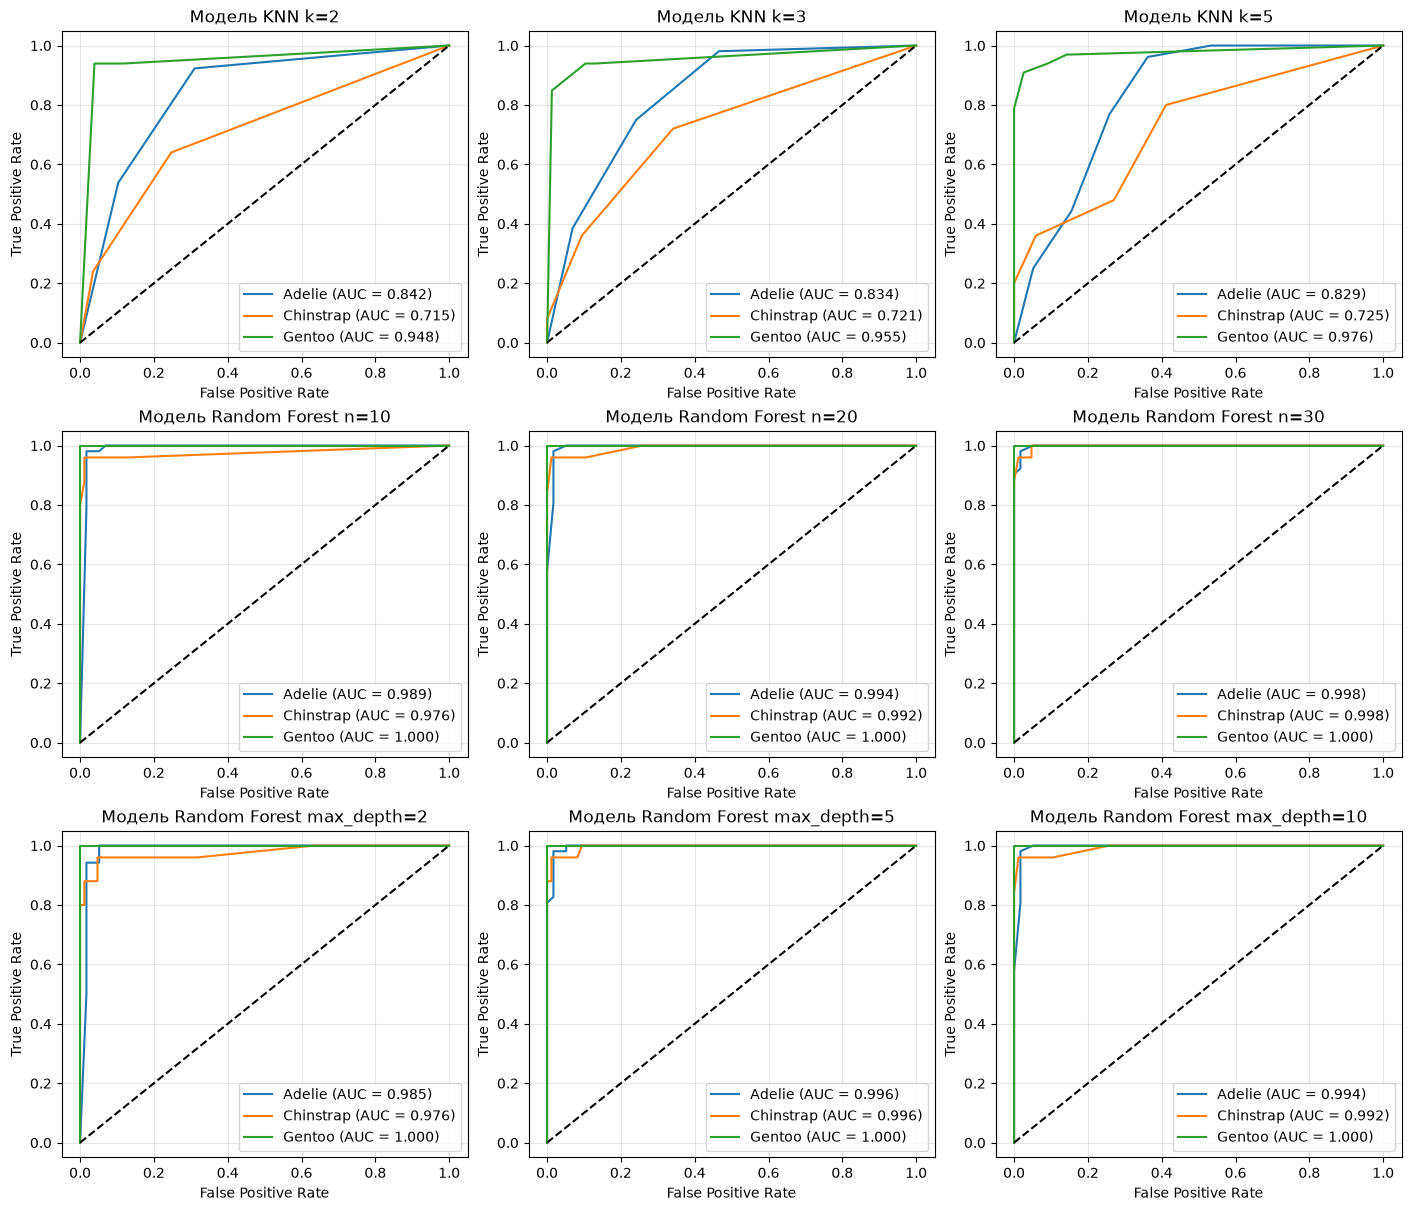

In [111]:
import math

ncols = 3
nrows = math.ceil(len(models) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 4 * nrows),
    squeeze=False,
    layout="constrained"
)

for ax, (name, model) in zip(axes.flat, models.items()):
    draw_all_rocs(model, x_test, y_test, f"Модель {name}", ax)

# Скрываем пустые области, если число моделей нечётное
for ax in list(axes.flat)[len(models):]:
    ax.set_visible(False)

plt.show()

**Разбор результатов**

ROC-кривые построены отдельно для каждого вида по схеме "один против остальных". Они показывают соотношение доли правильно найденных объектов вида (TPR) и доли ложных срабатываний (FPR) при изменении порога вероятности. Чем ближе кривая к левому верхнему углу и чем больше AUC, тем лучше модель отделяет данный вид от остальных.

У KNN лучше всего отделяется Gentoo: AUC возрастает примерно от 0.948 при k=2 до 0.976 при k=5. Наименьший AUC наблюдается для Chinstrap - от 0.715 до 0.725; для Adelie он составляет около 0.829–0.842. Это согласуется с трудностями распознавания Chinstrap, отмеченными при анализе метрик и матриц ошибок.

У всех вариантов случайного леса AUC для Gentoo равен 1.000, а для остальных видов превышает 0.976. Наилучшие значения для Adelie и Chinstrap получены при 30 деревьях: около 0.998 для каждого класса. Высокий AUC характеризует качество ранжирования объектов по вероятности и не гарантирует отсутствия ошибок при выборе класса через predict.

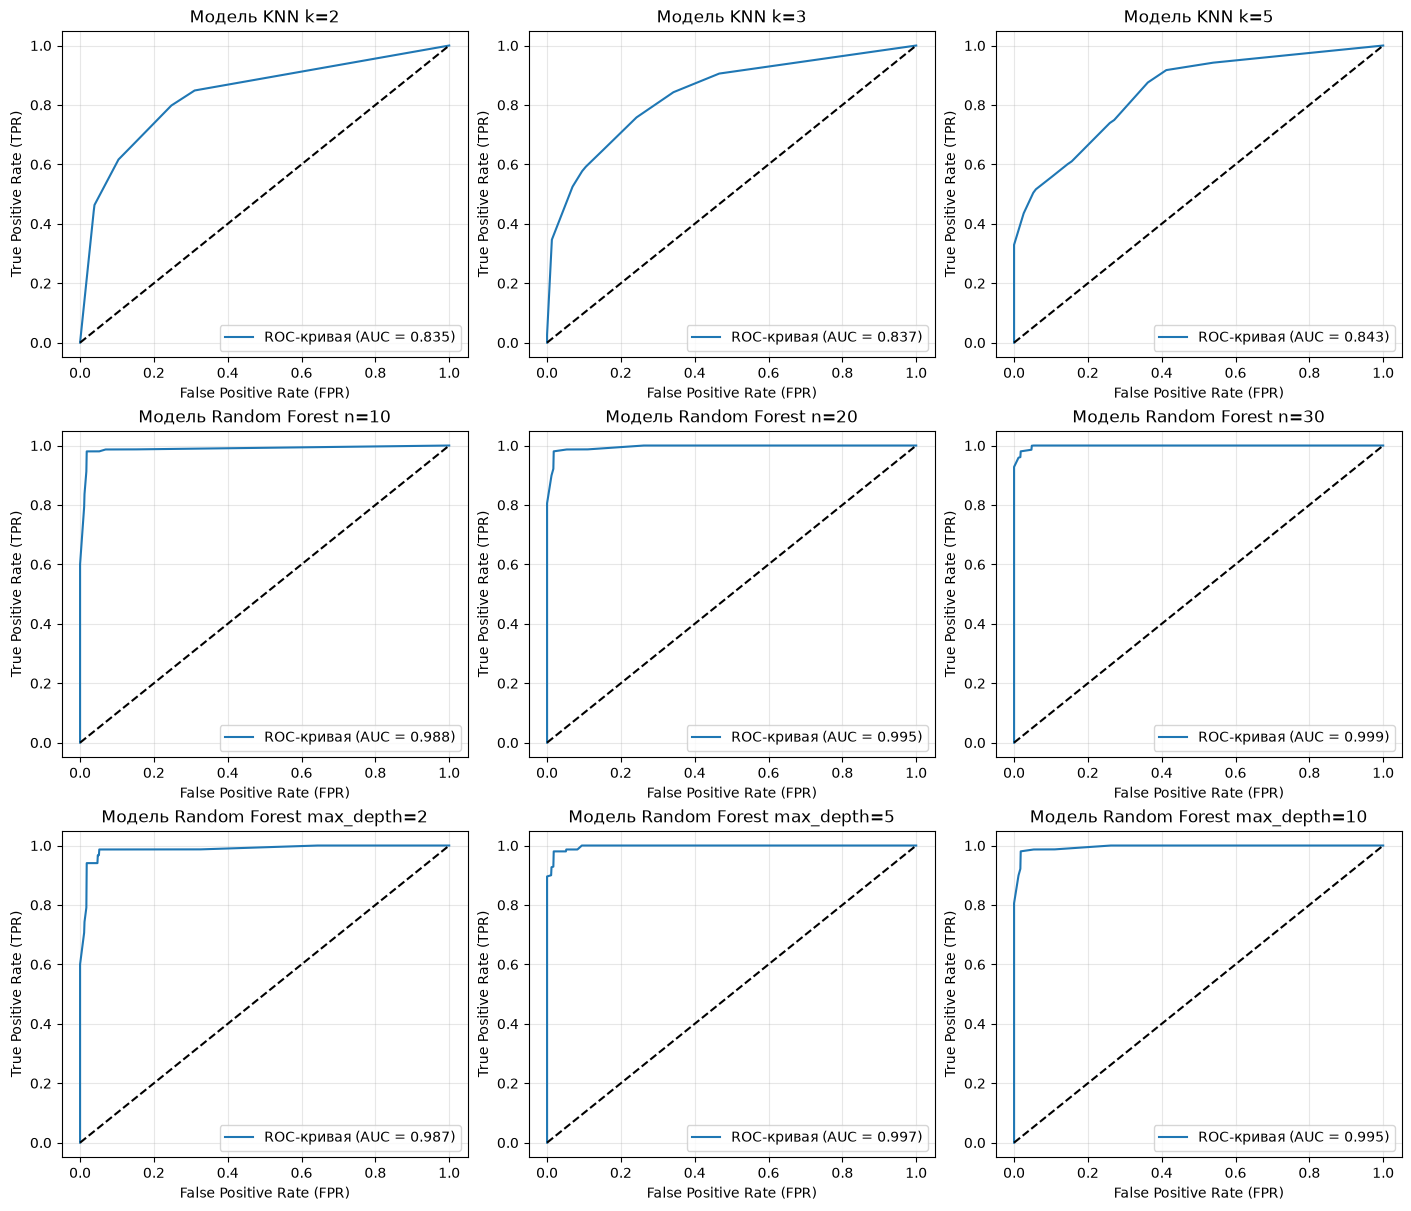

In [110]:
ncols = 3
nrows = math.ceil(len(models) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 4 * nrows),
    squeeze=False,
    layout="constrained"
)

for ax, (name, model) in zip(axes.flat, models.items()):
    draw_median_roc(model, x_test, y_test, f"Модель {name}", ax)

# Скрываем пустые области, если число моделей нечётное
for ax in list(axes.flat)[len(models):]:
    ax.set_visible(False)

plt.show()

**Разбор результатов**

На этих графиках показано макроусреднение ROC-кривых: TPR каждого класса интерполируется на общую сетку FPR, после чего значения усредняются с одинаковыми весами. Поэтому каждый вид вносит одинаковый вклад независимо от числа объектов.

Для KNN усреднённый AUC составляет примерно 0.835 при k=2, 0.837 при k=3 и 0.843 при k=5. У случайного леса значения значительно выше: от 0.987 при max_depth=2 до 0.999 при 30 деревьях. При 20 деревьях AUC составляет около 0.995, а при max_depth=5 - 0.997. Таким образом, по качеству ранжирования среди KNN лучше k=5, а среди рассмотренных случайных лесов - вариант с 30 деревьями.

Вертикальные участки при FPR=0 означают, что часть объектов удаётся распознать без ложных срабатываний. После интерполяции средний TPR на верхнем конце такого участка, например для max_depth=5, составляет около 0.896. Добавленная точка (0, 0) сохраняет начало ROC-кривой и отображает этот вертикальный подъём, не изменяя площадь под кривой.

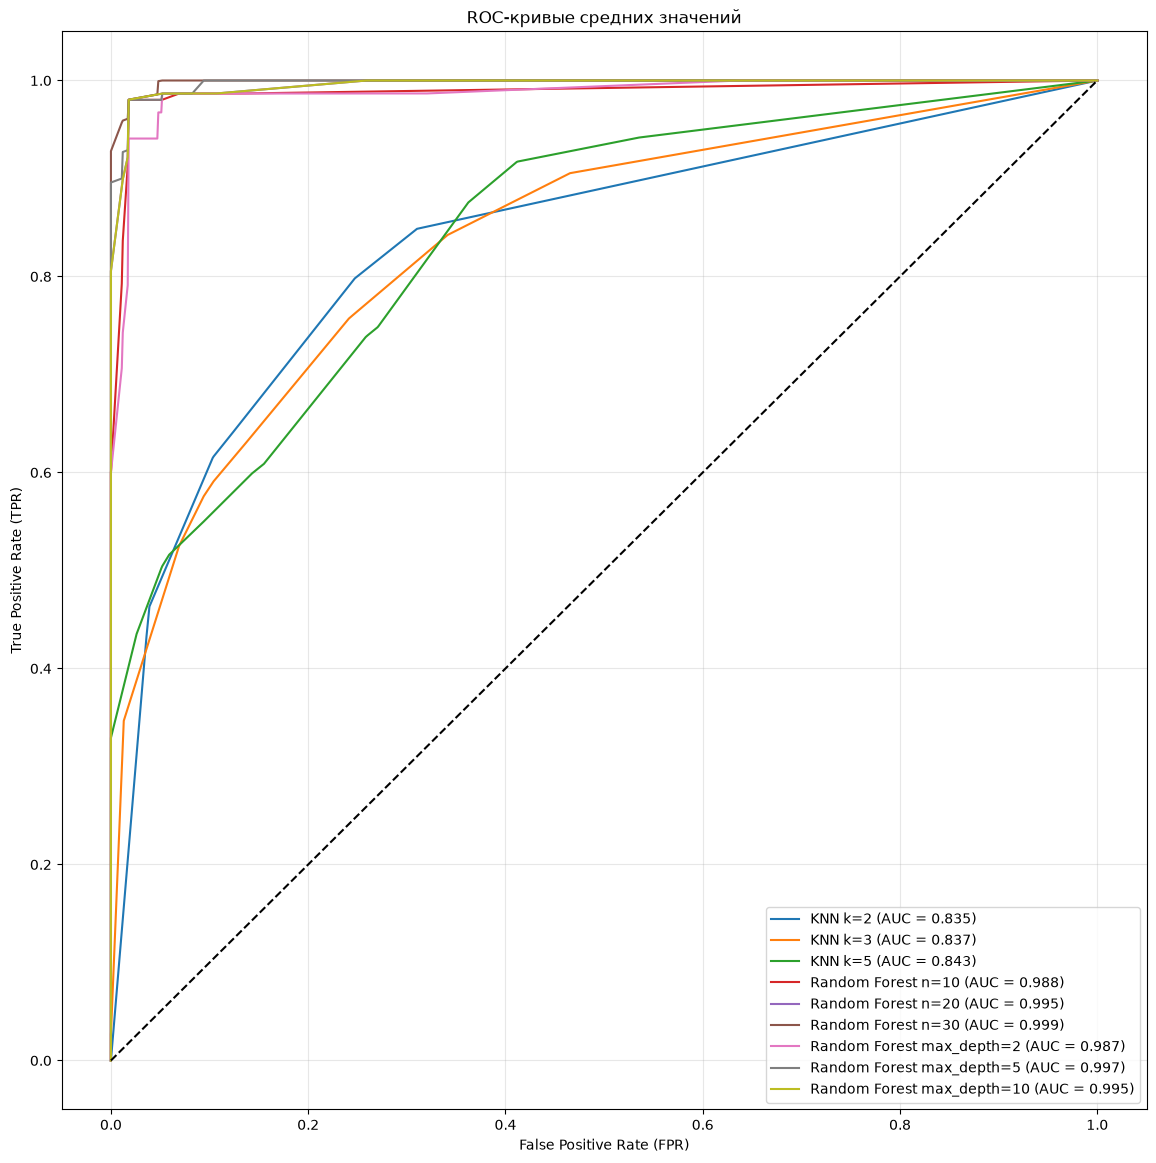

In [117]:
# Отобразим все ROC-кривые на одном графике
show_all_median_roc(models)

**Разбор результатов**

Совмещённый график показывает, что случайный лес по ROC AUC превосходит все рассмотренные варианты KNN. Кривые случайных лесов расположены близко к левому верхнему углу, а их AUC составляет примерно 0.987-0.999 против 0.835-0.843 у KNN. При этом разница между конфигурациями случайного леса существенно меньше, чем между двумя методами.

Максимальный усреднённый ROC AUC получен у случайного леса с 30 деревьями (около 0.999). Однако максимальная Accuracy достигается при 20 деревьях, а также при max_depth=5 и max_depth=10 (0.982). Противоречия здесь нет: ROC AUC оценивает ранжирование вероятностей при разных порогах, тогда как Accuracy оценивает конкретные предсказанные классы.

Для текущего разбиения случайный лес с 20 деревьями можно выбрать как вариант с высокой Accuracy и macro F1. Ограничение глубины до 5 сохраняет эти метрики и даёт несколько больший ROC AUC. 